# Homework 4 卷积神经网络：人脸性别分类

Author: Lianjie (Marc) Shi  


要求：在这一周的学习中，我们学习了卷积神经网络的基础知识。本周的作业目标为：依然使用上次作业的数据，模仿课堂代码，实现性别分类的任务（每张图片的性别标签记录在Facescore.csv中，图片文件名首字母分为'f'(female)和'm'(male)）。具体要求为：
- 【1】代码应包含完整的流程（50分），包括数据读取（数据集构造、训练测试切分、生成器、数据展示）；自定义模型搭建（定义模型类，实例化后展示模型summary）；模型训练（定义损失函数，优化器，监控指标，进行训练）；模型推断（从测试集取出5张图片+自己上传的3张图片进行性别分类，输出预测结果）；
- 【2】训练测试切分比例固定为(7:3) （不满足要求扣10分），假设训练完成后CNN模型在【验证集】上的分类精度为x，则你的模型精度得分为 20*x ；
- 【3】请对比CNN模型和普通逻辑回归的结果（10分）；
- 【4】仿照课件取出卷积层的权重和被卷积的特征图进行可视化，谈一谈你的理解 (10分) 
- 【5】利用训练好的模型进行预测，适当的文字说明，报告的美观程度 (10分) ；
- 【6】请提交【PDF】版本的作业（非PDF版本扣10分）：先将包含代码和运行结果的.ipynb文件输出为html文件，再将html文件通过【打印】输出为【PDF】格式。【提示】可自行搭建神经网络（包括卷积池化），图片的尺寸可自由调整，训练过程中的各种超参数，均可自由调整。

## 0. 导入与随机种子

固定 random / numpy / torch / CUDA 的全部随机种子，保证初始权重、数据切分、batch 打乱顺序每次都相同，结果完全可复现。

In [3]:
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt


def set_seed(seed=1):
    """固定全部随机种子，保证结果可复现。"""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True  # 每次选择相同的卷积算法
    torch.backends.cudnn.benchmark = False


set_seed(1)  # 随机种子：不改这里，每次运行的结果就一样

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"使用设备: {device}")
print(f"PyTorch 版本: {torch.__version__}")

使用设备: cuda
PyTorch 版本: 2.14.1+cu130


## 1. 数据读取

### 1.1 读取 CSV 并构造性别标签

`FaceScore.csv` 中每行记录图片文件名与颜值评分，**性别由文件名首字母决定**：`'f'` → 女性（标签 0），`'m'` → 男性（标签 1）。

In [4]:
csv_path = 'data/faces/FaceScore.csv'
MasterFile = pd.read_csv(csv_path)

# 由文件名首字母构造性别标签: 'f'(female)->0, 'm'(male)->1
MasterFile['Gender'] = (MasterFile['Filename'].str[0] == 'm').astype(int)  # 0=女, 1=男
MasterFile['GenderLabel'] = MasterFile['Gender'].map({0: 'female', 1: 'male'})

print(MasterFile.shape)
MasterFile.head()

(5500, 4)


,Filename,Rating,Gender,GenderLabel
0,ftw1.jpg,4.083333,0,female
1,ftw10.jpg,3.666667,0,female
2,ftw100.jpg,1.916667,0,female
3,ftw101.jpg,2.416667,0,female
4,ftw102.jpg,3.166667,0,female


GenderLabel
female    2750
male      2750
Name: count, dtype: int64


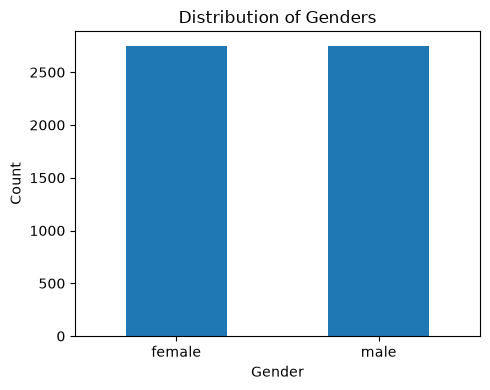

In [5]:
# 性别分布可视化
counts = MasterFile['GenderLabel'].value_counts()
print(counts)

plt.figure(figsize=(5, 4))
counts.plot(kind='bar')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.title('Distribution of Genders')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**分析**：数据集共 5500 张人脸图像，女性（`f` 开头）和男性（`m` 开头）各 2750 张。

### 1.2 定义 Dataset 类

In [6]:
from itertools import islice
from PIL import Image
from torch.utils.data import Dataset


def default_loader(path):
    return Image.open(path).convert('RGB')


class FaceGenderDataset(Dataset):
    def __init__(self, csv_file='data/faces/FaceScore.csv',
                 img_dir='data/faces/images/',
                 loader=default_loader, transform=None):
        imgs = []
        with open(csv_file, 'r') as f:
            for line in islice(f, 1, None):  # 跳过表头
                line = line.strip('\n').split(',')
                img_path = img_dir + line[0]
                gender = 0 if line[0][0] == 'f' else 1  # 'f'->女(0), 'm'->男(1)
                imgs.append((img_path, gender))
        self.imgs = imgs
        self.loader = loader
        self.transform = transform

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, index):
        img_path, label = self.imgs[index]
        img = self.loader(img_path)
        if self.transform:
            img = self.transform(img)
        return img, label


print(f"数据集大小: {len(FaceGenderDataset())}")

数据集大小: 5500


### 1.3 训练测试切分（**固定 7:3**）

In [ ]:
from torch.utils.data import random_split

transform = transforms.Compose([
    transforms.Resize((128, 128)),  
    transforms.ToTensor(),          # 转为 [0,1] 的 tensor
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),  # 归一化到[-1,1](仿课件MNIST): 零均值输入让CNN收敛更快
])

full_data = FaceGenderDataset(transform=transform)

# 作业要求: 训练测试切分比例固定为 7:3
train_size = int(len(full_data) * 0.7)
val_size = len(full_data) - train_size
train_set, val_set = random_split(full_data, [train_size, val_size])

print(f"训练集大小: {len(train_set)}")
print(f"验证集大小: {len(val_set)}")  # 验证集=7:3切分出的30%测试部分, 全作业仅此一个

训练集大小: 3849
验证集大小: 1651


### 1.4 一次性将全部数据载入显存

In [ ]:
def preload_to_gpu(dataset):
    imgs, labels = [], []
    for i in range(len(dataset)):
        x, y = dataset[i]
        imgs.append(x)
        labels.append(y)
    X = torch.stack(imgs).to(device)
    y = torch.tensor(labels, dtype=torch.long).to(device)  # 分类标签用 long
    return X, y


class GPUDataset(torch.utils.data.Dataset):
    """数据常驻显存: __getitem__ 直接返回 GPU 张量的切片。"""
    def __init__(self, X, y):
        self.X, self.y = X, y
    def __len__(self):
        return len(self.X)
    def __getitem__(self, i):
        return self.X[i], self.y[i]


train_X, train_y = preload_to_gpu(train_set)
val_X, val_y = preload_to_gpu(val_set)
train_set = GPUDataset(train_X, train_y)  
val_set = GPUDataset(val_X, val_y)
print(f"训练数据: {tuple(train_X.shape)}, 显存占用约 {train_X.element_size() * train_X.nelement() / 2**20:.0f} MiB")
print(f"验证数据: {tuple(val_X.shape)}, 显存占用约 {val_X.element_size() * val_X.nelement() / 2**20:.0f} MiB")

训练数据: (3849, 3, 128, 128), 显存占用约 722 MiB
验证数据: (1651, 3, 128, 128), 显存占用约 310 MiB


### 1.5 定义数据生成器 DataLoader

In [9]:
batch_size = 128
train_loader = torch.utils.data.DataLoader(
    train_set, batch_size=batch_size, shuffle=True, num_workers=0)
val_loader = torch.utils.data.DataLoader(
    val_set, batch_size=batch_size, shuffle=False, num_workers=0)

print(f"训练 batch 数: {len(train_loader)}")
print(f"验证 batch 数: {len(val_loader)}")

训练 batch 数: 31
验证 batch 数: 13


### 1.6 数据展示

In [ ]:
from torchvision.utils import make_grid

images, labels = next(iter(train_loader))
images = images.cpu() * 0.5 + 0.5  # 反归一化到[0,1]便于显示(Normalize后张量在[-1,1])
print(f"图片张量形状: {images.shape}")  # [batch_size, C, H, W]
print(f"标签张量形状: {labels.shape}")

plt.figure(figsize=(12, 20))
plt.axis('off')
plt.imshow(make_grid(images, nrow=8).permute((1, 2, 0)))
plt.title('A batch of training faces')
plt.show()

# 打印前 16 张的性别标签
id2gender = {0: 'female', 1: 'male'}
print([id2gender[l] for l in labels[:16].tolist()])

**分析**：训练 batch 的图片张量形状为 `(128, 3, 128, 128)`，标签为 0/1 整数。从展示的人脸可以看出，数据集中同时包含女性（标签 0）和男性（标签 1）样本，且已完成 128×128 缩放与 [0,1] 归一化。

## 2. 自定义模型搭建

模仿课堂 LeNet-5 的结构（`conv` + `fc` 两个 `nn.Sequential`，forward 中先卷积再 flatten 拉直），针对本任务做两处适配：

1. 输入为 3 通道 128×128 的 RGB 人脸图像；
2. 输出改为 2 维（女/男二分类）。

In [11]:
# 定义性别分类 CNN (LeNet-5 风格)
class GenderLeNet(nn.Module):
    def __init__(self):
        super(GenderLeNet, self).__init__()  # 直接继承nn.Module的init
        ## 构建卷积层: 128 -> conv5(124) -> pool(62) -> conv5(58) -> pool(29)
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=5, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(16, 32, 5),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        ## 构建全连接层: 32*29*29 为卷积层的输出维数
        self.fc = nn.Sequential(
            nn.Linear(32 * 29 * 29, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 2)  # 2 = 女/男两个类别; 只线性变换, softmax在交叉熵损失内
        )

    def forward(self, x):
        feature = self.conv(x)
        output = self.fc(feature.view(x.size()[0], -1))  # flatten拉直后再输入全连接层
        return output

model = GenderLeNet()
print(model)

GenderLeNet(
  (conv): Sequential(
    (0): Conv2d(3, 16, kernel_size=(5, 5), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(5, 5), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc): Sequential(
    (0): Linear(in_features=26912, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)


In [12]:
# 查看模型具体信息
from torchsummary import summary  

IMSIZE = 128
model = GenderLeNet().to(device)  
summary(model, (3, IMSIZE, IMSIZE))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 16, 124, 124]           1,216
              ReLU-2         [-1, 16, 124, 124]               0
         MaxPool2d-3           [-1, 16, 62, 62]               0
            Conv2d-4           [-1, 32, 58, 58]          12,832
              ReLU-5           [-1, 32, 58, 58]               0
         MaxPool2d-6           [-1, 32, 29, 29]               0
            Linear-7                  [-1, 128]       3,444,864
              ReLU-8                  [-1, 128]               0
            Linear-9                   [-1, 64]           8,256
             ReLU-10                   [-1, 64]               0
           Linear-11                    [-1, 2]             130
Total params: 3,467,298
Trainable params: 3,467,298
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.19
Forw

**分析**：模型总结：两次「卷积→ReLU→池化」后接三层全连接层。输入 3×128×128，经卷积与池化后特征图缩小为 32×29×29（尺寸越来越小、通道越来越深），flatten 成 26912 维向量后逐层压缩到 2 维输出。参数量主要集中在第一个全连接层，整个模型约 347 万参数，远小于 HW3 的全连接网络（1260 万），体现了卷积权值共享带来的参数效率。

## 3. 模型训练

- **损失函数**：`nn.CrossEntropyLoss`（内部包含 softmax，因此模型最后一层不接 softmax）
- **优化器**：Adam，学习率 1e-3
- **监控指标**：训练损失、训练准确率、验证损失、验证准确率（每个 epoch 打印一次；验证集即 7:3 切分出的 30% 部分，本作业只有这一个验证集）

In [13]:
import time


def train(model, train_loader, val_loader, epochs, lr):
    """训练并在每个 epoch 结束后评估验证集(7:3切分出的30%), 返回四条曲线数据。"""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)  # 设置优化器
    criterion = nn.CrossEntropyLoss()  # 交叉熵损失, 内部包含 softmax
    train_losses, train_accs, val_losses, val_accs = [], [], [], []
    for epoch in range(epochs):
        model.train()
        start = time.time()
        running_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:  # 数据已常驻显存, 逐batch切片
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
        train_loss = running_loss / total
        train_acc = correct / total

        model.eval()
        val_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                val_loss += criterion(outputs, labels).item() * images.size(0)
                correct += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)
        val_loss /= total
        val_acc = correct / total

        train_losses.append(train_loss)
        train_accs.append(train_acc)
        val_losses.append(val_loss)
        val_accs.append(val_acc)
        print(f"Epoch [{epoch + 1}/{epochs}], time: {time.time() - start:.2f}s, "
              f"loss: {train_loss:.4f}, acc: {train_acc:.4f}, "
              f"val_loss: {val_loss:.4f}, val_acc: {val_acc:.4f}")
    return train_losses, train_accs, val_losses, val_accs


# 给定超参数，进行模型训练
epochs = 30  # 训练周期数
lr = 1e-3    # 学习率
train_losses, train_accs, val_losses, val_accs = train(model, train_loader, val_loader, epochs=epochs, lr=lr)

Epoch [1/30], time: 1.12s, loss: 0.5383, acc: 0.7228, val_loss: 0.4395, val_acc: 0.7910
Epoch [2/30], time: 0.90s, loss: 0.3823, acc: 0.8327, val_loss: 0.2987, val_acc: 0.8643
Epoch [3/30], time: 0.88s, loss: 0.2667, acc: 0.8880, val_loss: 0.3276, val_acc: 0.8637
Epoch [4/30], time: 0.87s, loss: 0.2571, acc: 0.8878, val_loss: 0.2226, val_acc: 0.9073
Epoch [5/30], time: 0.83s, loss: 0.1623, acc: 0.9327, val_loss: 0.1884, val_acc: 0.9237
Epoch [6/30], time: 0.81s, loss: 0.1265, acc: 0.9491, val_loss: 0.1977, val_acc: 0.9200
Epoch [7/30], time: 0.80s, loss: 0.0998, acc: 0.9613, val_loss: 0.2149, val_acc: 0.9231
Epoch [8/30], time: 0.81s, loss: 0.0887, acc: 0.9652, val_loss: 0.2008, val_acc: 0.9267
Epoch [9/30], time: 0.80s, loss: 0.0751, acc: 0.9717, val_loss: 0.1968, val_acc: 0.9285
Epoch [10/30], time: 0.82s, loss: 0.0446, acc: 0.9821, val_loss: 0.2279, val_acc: 0.9291
Epoch [11/30], time: 0.82s, loss: 0.0343, acc: 0.9878, val_loss: 0.2113, val_acc: 0.9352
Epoch [12/30], time: 0.79s, lo

## 4. 训练过程可视化

> 每个 epoch 的 val_loss/val_acc 仅为监控指标；官方评分精度 x 由 4.1 节专门验证 cell 计算（对应 HW3 的 2.11）。

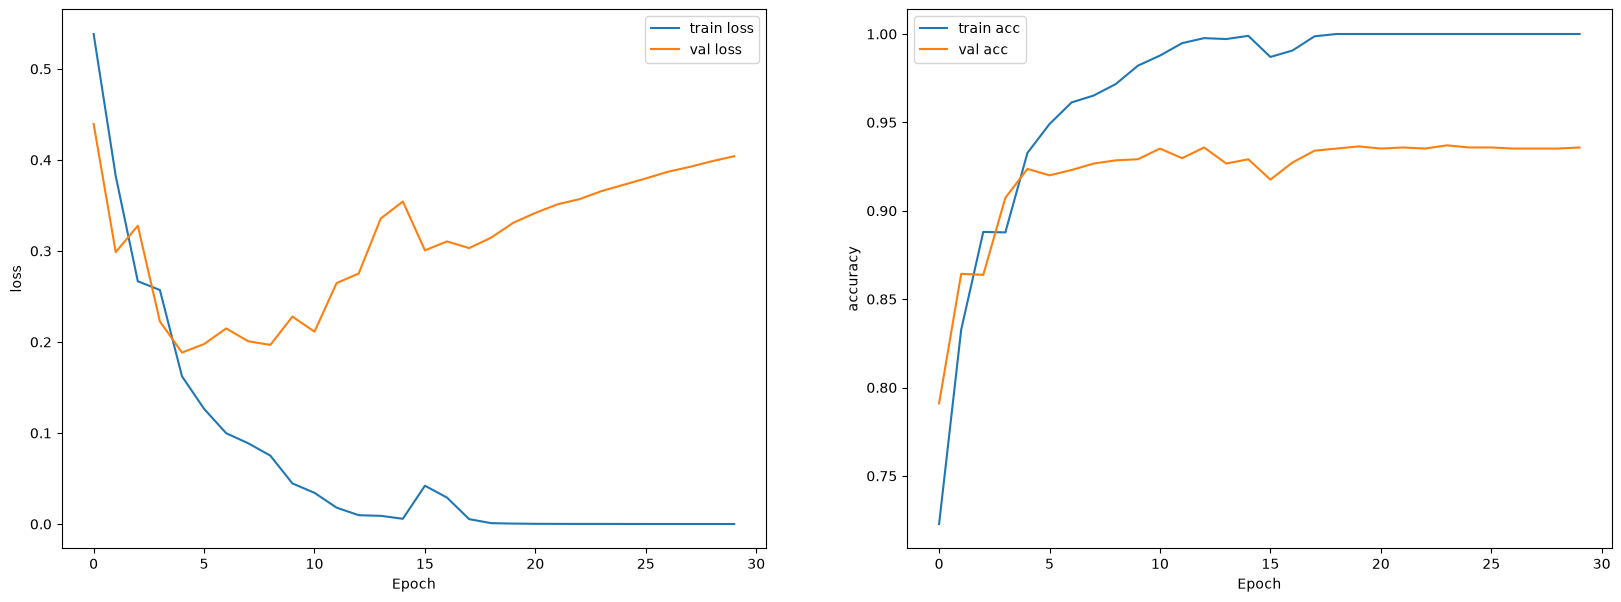

最终监控值: train_loss=0.0000, train_acc=1.0000, val_loss=0.4040, val_acc=0.9358


In [14]:
# 训练集的误差曲线和验证集的准确率曲线可视化 (仿课堂代码5-6)
plt.figure(figsize=(20, 7))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='train loss')
plt.plot(val_losses, label='val loss')
plt.xlabel("Epoch")
plt.ylabel("loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accs, label='train acc')
plt.plot(val_accs, label='val acc')
plt.xlabel("Epoch")
plt.ylabel("accuracy")
plt.legend()

plt.show()

# 注: 每个epoch的 val_loss/val_acc 只是训练过程中的监控指标;
#     官方的作业评分精度 x 在下一节(4.1)用训练好的模型在整个验证集上单独计算, 与 HW3 的 2.11 一致。
print(f"最终监控值: train_loss={train_losses[-1]:.4f}, train_acc={train_accs[-1]:.4f}, "
      f"val_loss={val_losses[-1]:.4f}, val_acc={val_accs[-1]:.4f}")

### 4.1 计算验证集分类精度 x 与模型精度得分

下面用**训练好的模型在整个验证集（7:3 切分出的 30%，全作业仅此一个）上评估一次**，得到作业评分用的精度 x。

In [15]:
# 4.1 计算验证集分类精度 x 与模型精度得分
# 根据 HW4 要求: 训练完成后CNN模型在【验证集】上的分类精度为 x, 模型精度得分 = 20 * x
model.eval()
val_predictions = []
val_labels_list = []
with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        preds = model(images).argmax(1)  # 获取预测类别
        val_predictions.append(preds)
        val_labels_list.append(labels)

val_predictions = torch.cat(val_predictions)
val_labels = torch.cat(val_labels_list)

x = (val_predictions == val_labels).float().mean().item()
score = 20 * x

print(f"验证集分类精度 (x): {x:.6f}")
print(f"模型精度得分 (20 * x): {score:.6f}")

验证集分类精度 (x): 0.935796
模型精度得分 (20 * x): 18.715929


**分析**：前期收敛很快：前 4 个 epoch 训练损失从约 0.53 降到 0.2 以下，准确率升到约 0.93，说明归一化输入下 CNN 能快速学到有效的性别特征；
后期出现过拟合：训练损失继续降到接近 0、训练准确率达 100%，而验证损失从最低点约 0.19 回升到 0.40，训练/验证准确率差距约 6.4 个百分点；
最终成绩：训练完成后验证集分类精度 x = 0.9358，模型精度得分 = 20 × x ≈ 18.72（满分 20）。

## 5. 模型推断（Inference）

### 5.1 从验证集（测试集）取出 5 张图片进行性别分类

In [ ]:
dataiter = iter(val_loader)
images, labels = next(dataiter)

model.eval()
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i in range(5):
    img = images[i].permute(1, 2, 0).cpu().numpy() * 0.5 + 0.5  # 反归一化到[0,1]显示
    true_gender = id2gender[labels[i].item()]

    with torch.no_grad():
        prob = torch.softmax(model(images[i].unsqueeze(0).to(device)), dim=1)
        pred_gender = id2gender[prob.argmax(1).item()]
        confidence = prob.max().item()

    color = 'green' if pred_gender == true_gender else 'red'
    axes[i].imshow(img)
    axes[i].set_title(f"Pred: {pred_gender} ({confidence:.2f})\nTrue: {true_gender}", color=color)
    axes[i].axis('off')
plt.tight_layout()
plt.show()

## 6. 对比：CNN vs 普通逻辑回归

普通逻辑回归采用课堂（Lecture 4）的做法：把 128×128×3 的图像**直接展平成 49152 维向量**，只用一个线性层做二分类；而 CNN 通过卷积核提取局部空间特征。两者使用**完全相同**的 7:3 切分、DataLoader、损失函数、优化器与训练流程，对比是公平的。

### 6.1 定义逻辑回归模型

In [18]:
# 构建逻辑回归模型
class LogisticRegression(nn.Module):
    def __init__(self):
        super(LogisticRegression, self).__init__()
        self.linear = nn.Linear(128 * 128 * 3, 2)  # 展平后的像素 -> 女/男两类

    def forward(self, x):
        x = x.reshape(-1, 128 * 128 * 3)  # 将图像展平为一维向量
        x = self.linear(x)
        # x = F.log_softmax(x, dim=1)  # 不使用: CrossEntropyLoss内部已包含softmax
        return x

lr_model = LogisticRegression().to(device)
print(lr_model)

LogisticRegression(
  (linear): Linear(in_features=49152, out_features=2, bias=True)
)


In [19]:
# 查看模型具体信息
summary(lr_model, (3, IMSIZE, IMSIZE))  # 第一个参数为模型, 第二个参数为输入尺寸(3维)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                    [-1, 2]          98,306
Total params: 98,306
Trainable params: 98,306
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.19
Forward/backward pass size (MB): 0.00
Params size (MB): 0.38
Estimated Total Size (MB): 0.56
----------------------------------------------------------------


**分析**：逻辑回归只有一个线性层，参数量 = (128×128×3 + 1) × 2 = **98,306**，直接把每个像素当作独立特征做线性加权；参数量不到 CNN（约 347 万）的 3%，模型容量和先验假设（线性、无空间结构）都弱得多。

### 6.2 训练逻辑回归（与 CNN 相同的 train 流程）
逻辑回归模型同样从 `train_loader` 逐 batch 取显存切片训练，损失函数（交叉熵）、优化器（Adam, lr=1e-3）、监控指标（loss/acc）与 CNN 完全一致。

In [20]:
# 与CNN完全相同的训练流程
lr_epochs = 30  # 与CNN的epoch数保持一致, 对比公平
lr_train_losses, lr_train_accs, lr_val_losses, lr_val_accs = train(
    lr_model, train_loader, val_loader, epochs=lr_epochs, lr=1e-3)

Epoch [1/30], time: 0.13s, loss: 3.2501, acc: 0.7054, val_loss: 2.0564, val_acc: 0.7377
Epoch [2/30], time: 0.13s, loss: 1.0493, acc: 0.8028, val_loss: 1.3979, val_acc: 0.7280
Epoch [3/30], time: 0.12s, loss: 0.6516, acc: 0.8270, val_loss: 0.6791, val_acc: 0.8225
Epoch [4/30], time: 0.12s, loss: 0.4707, acc: 0.8446, val_loss: 0.4997, val_acc: 0.8359
Epoch [5/30], time: 0.11s, loss: 0.3520, acc: 0.8717, val_loss: 0.4067, val_acc: 0.8601
Epoch [6/30], time: 0.11s, loss: 0.4137, acc: 0.8545, val_loss: 0.5402, val_acc: 0.8371
Epoch [7/30], time: 0.11s, loss: 0.3380, acc: 0.8740, val_loss: 1.4545, val_acc: 0.7056
Epoch [8/30], time: 0.12s, loss: 0.6458, acc: 0.8272, val_loss: 0.5599, val_acc: 0.8431
Epoch [9/30], time: 0.11s, loss: 0.6030, acc: 0.8358, val_loss: 0.9875, val_acc: 0.7813
Epoch [10/30], time: 0.11s, loss: 0.5348, acc: 0.8553, val_loss: 0.6010, val_acc: 0.8571
Epoch [11/30], time: 0.11s, loss: 0.4608, acc: 0.8693, val_loss: 0.7651, val_acc: 0.8207
Epoch [12/30], time: 0.11s, lo

### 6.3 CNN vs 逻辑回归 对比图

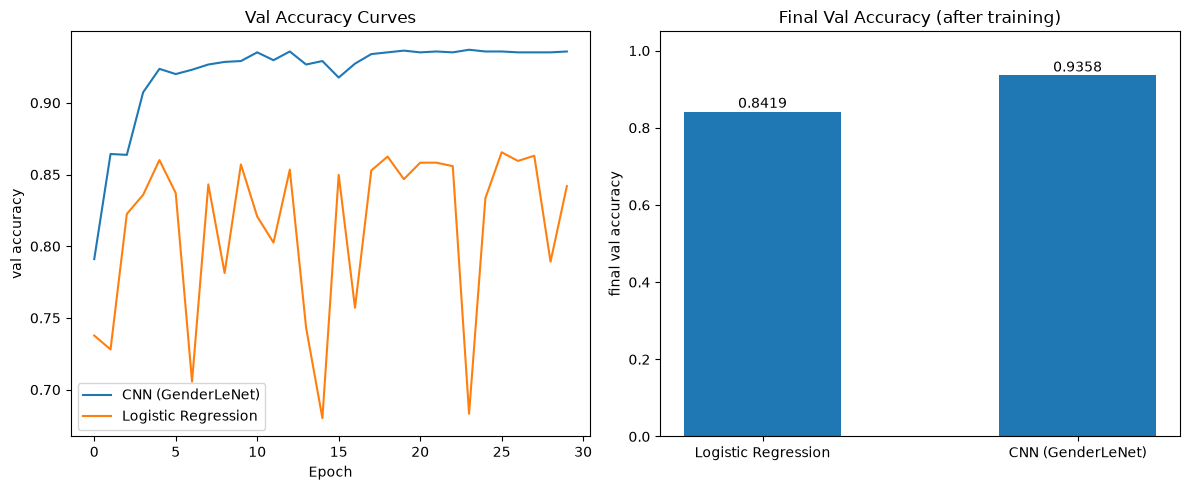

模型                    验证集准确率(训练完成后)           
------------------------------------------------
Logistic Regression   0.8419                  
CNN (GenderLeNet)     0.9358                  

CNN 相比逻辑回归提升: 9.39 个百分点


In [21]:
# 对比两者在同一个验证集(7:3切分出的30%)上、训练完成后的分类精度
# CNN: 用4.1节专门验证cell算出的官方验证精度 x
cnn_acc = x

# 逻辑回归: 同样用训练好的最终模型在整个验证集上评估一次, 与CNN口径完全一致
lr_model.eval()
lr_val_predictions = []
with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        lr_val_predictions.append(lr_model(images).argmax(1))
lr_val_predictions = torch.cat(lr_val_predictions)
lr_acc = (lr_val_predictions == val_labels).float().mean().item()

plt.figure(figsize=(12, 5))

# 左图: 验证准确率曲线对比
plt.subplot(1, 2, 1)
plt.plot(val_accs, label='CNN (GenderLeNet)')
plt.plot(lr_val_accs, label='Logistic Regression')
plt.xlabel('Epoch')
plt.ylabel('val accuracy')
plt.title('Val Accuracy Curves')
plt.legend()

# 右图: 训练完成后的验证准确率柱状图
plt.subplot(1, 2, 2)
bars = plt.bar(['Logistic Regression', 'CNN (GenderLeNet)'], [lr_acc, cnn_acc], width=0.5)
plt.ylabel('final val accuracy')
plt.ylim(0, 1.05)
plt.title('Final Val Accuracy (after training)')
for b, v in zip(bars, [lr_acc, cnn_acc]):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.01, f'{v:.4f}', ha='center')
plt.tight_layout()
plt.show()

print(f"{'模型':<22}{'验证集准确率(训练完成后)':<24}")
print('-' * 48)
print(f"{'Logistic Regression':<22}{lr_acc:<24.4f}")
print(f"{'CNN (GenderLeNet)':<22}{cnn_acc:<24.4f}")
print()
print(f"CNN 相比逻辑回归提升: {(cnn_acc - lr_acc) * 100:.2f} 个百分点")

**分析**：
收敛速度与稳定性：逻辑回归约 5 个 epoch 就收敛到 0.83~0.85，之后大幅震荡（最低跌到约 0.67）；CNN 前 5 个 epoch稳步从 0.79 上升到 0.93 左右，随后进入 0.93~0.94 的平稳期，曲线明显更稳；
最终精度差距明显：训练完成后，逻辑回归验证准确率仅 0.8419，CNN 达到 0.9358，后者高出 9.39 个百分点。原因在于逻辑回归是线性模型，把 49152 个像素当作彼此独立的特征加权求和，完全忽略了人脸的空间局部结构；而 CNN 通过卷积核在局部窗口共享权重，能从边缘、纹理逐步组合出与性别相关的部件特征；
关于过拟合：CNN 在训练集上同样存在过拟合（train_acc = 100%），学到的层级特征泛化能力更强，验证精度仍远超线性模型——这 9.39 个百分点的差距正是卷积结构带来的收益。

## 7. 卷积层可视化（仿照课件 5-7 ~ 5-10）

仿照课件，依次取出**浅层卷积核**、**浅层输出特征图**、**深层卷积核**、**深层输出特征图**进行可视化，观察网络逐层提取的特征如何变化。

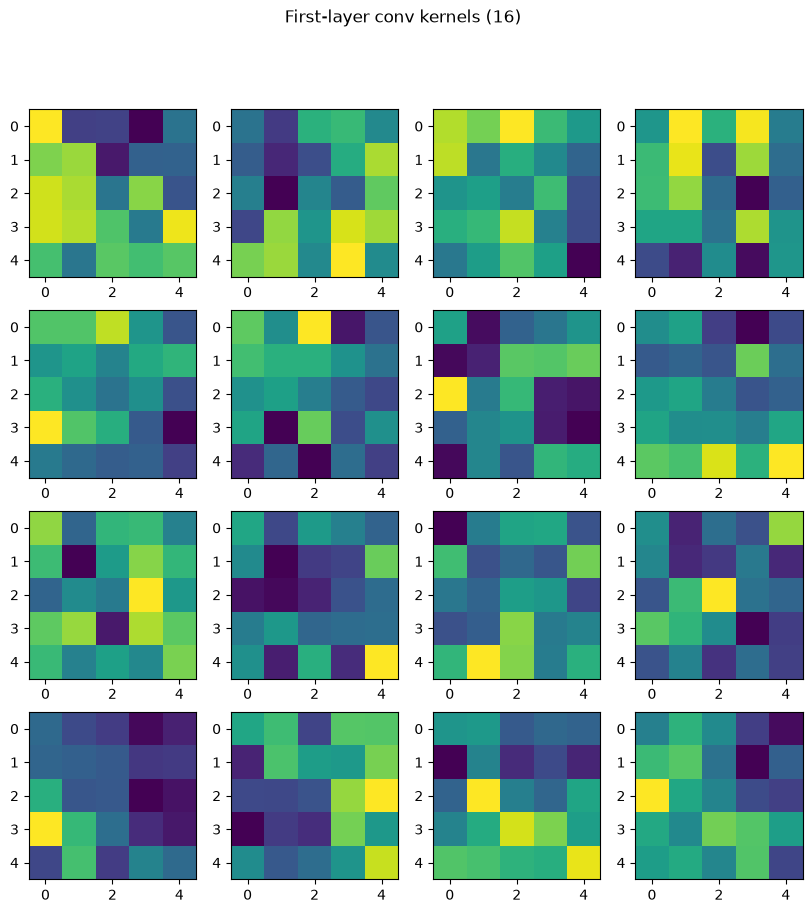

In [22]:
# 仿课件5-7: 第一层卷积核可视化 (16个 5x5x3 卷积核, 取RGB三通道均值显示)
plt.figure(figsize=(10, 10))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    target = model.conv[0].weight.cpu()
    kernel = target.data.numpy()[i]            # (3, 5, 5)
    plt.imshow(kernel.mean(axis=0))            # RGB通道求均值, 便于灰度显示
plt.suptitle('First-layer conv kernels (16)')
plt.show()

In [ ]:
# 仿课件5-8: 第一层卷积输出特征图可视化
model.eval()
input_x = val_set[0][0].unsqueeze(0).to(device)  # 从测试集取第1张图
with torch.no_grad():
    feature_map1 = model.conv[1](model.conv[0](input_x))  # 完成第一层卷积+激活: (1,16,124,124)
    input_x_2 = model.conv[2](feature_map1)               # 完成第一层池化
    feature_map2 = model.conv[4](model.conv[3](input_x_2))  # 完成第二层卷积+激活: (1,32,29,29)

# 原图
plt.figure(figsize=(3, 3))
plt.imshow(input_x[0].permute(1, 2, 0).cpu().numpy() * 0.5 + 0.5)  # 反归一化到[0,1]显示
plt.title(f"Input (true: {id2gender[val_set[0][1].item()]})")
plt.axis('off')
plt.show()

# 第一层卷积输出特征图 (16个通道)
plt.figure(figsize=(12, 12))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(feature_map1[0, i, ...].data.cpu().numpy())
plt.suptitle('First-layer feature maps (16 channels)')
plt.show()

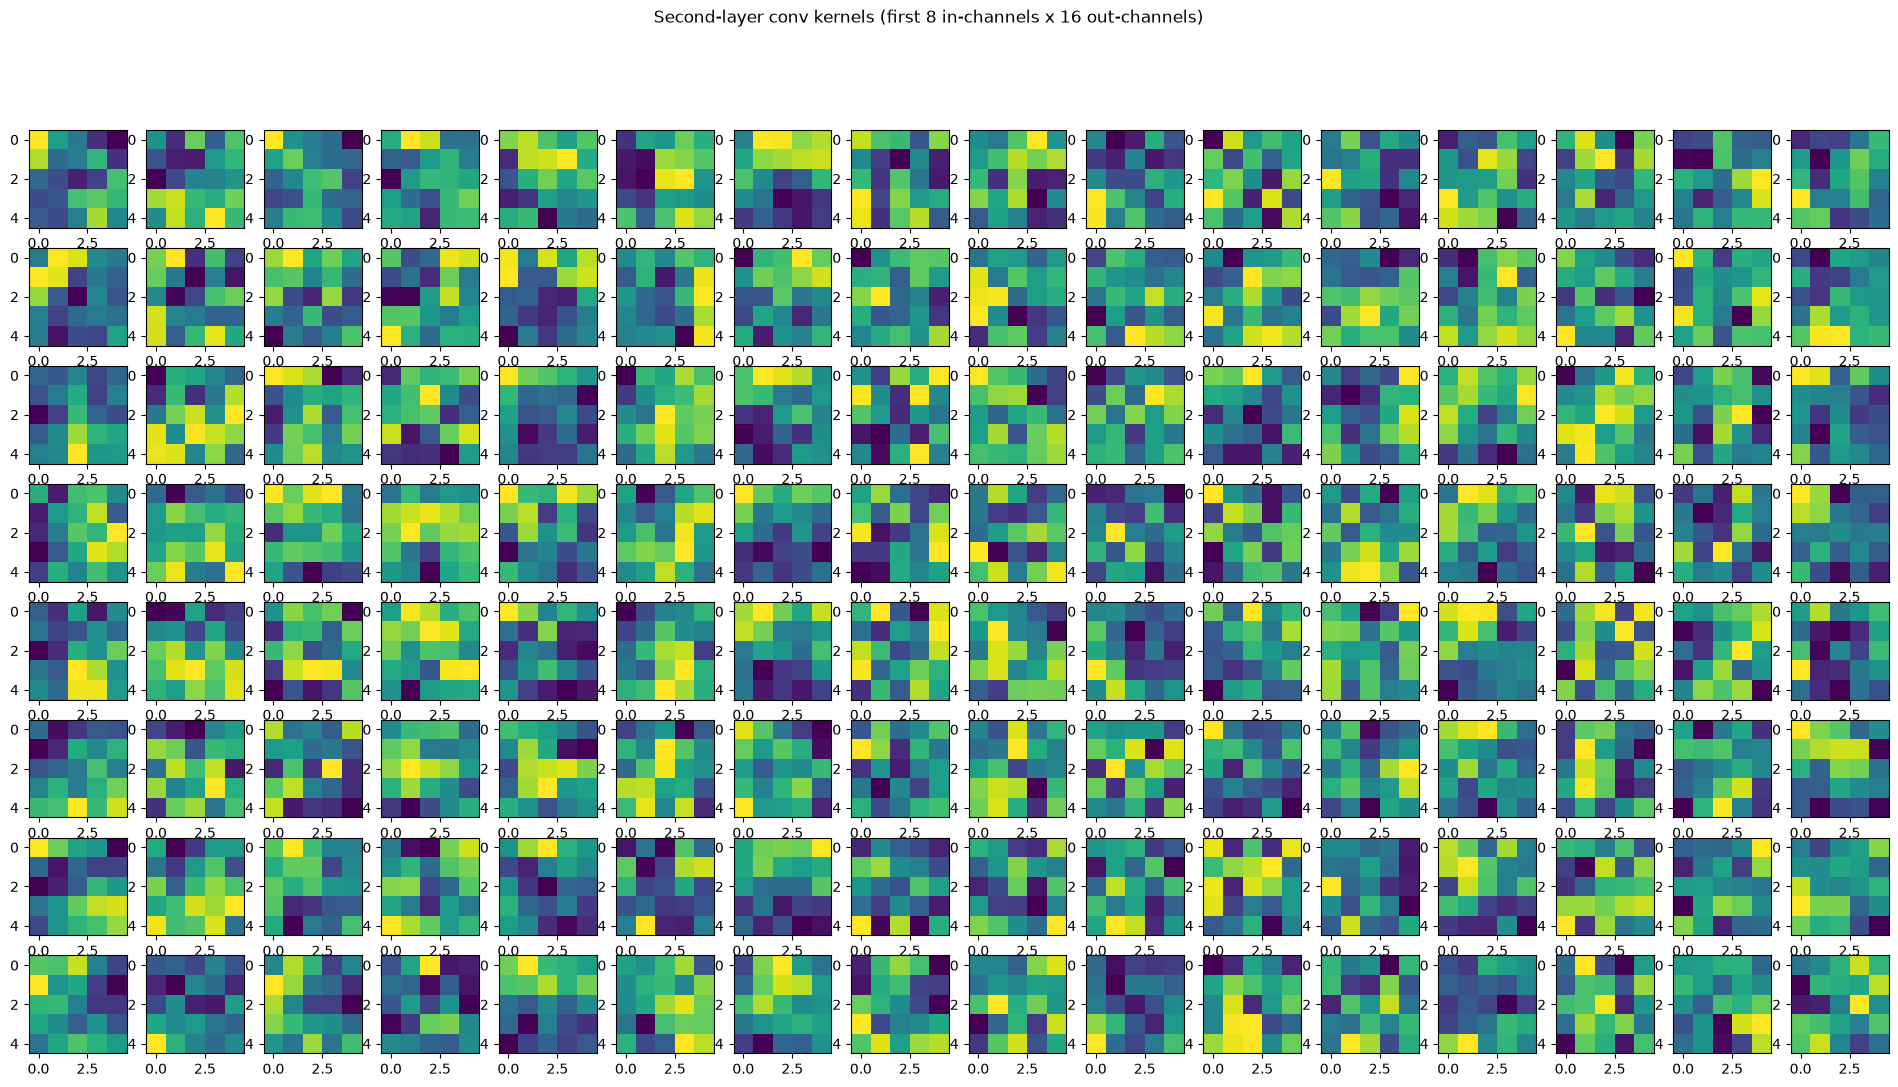

In [24]:
# 仿课件5-9: 第二层卷积核可视化 (形状 (32,16,5,5), 展示前8个输入通道 x 前16个输出通道)
plt.figure(figsize=(24, 12))
for i in range(8):
    for j in range(16):
        plt.subplot(8, 16, i * 16 + j + 1)
        plt.imshow(model.conv[3].weight.data.cpu().numpy()[j, i])  # [j,i]索引后已是(5,5)的单卷积核
plt.suptitle('Second-layer conv kernels (first 8 in-channels x 16 out-channels)')
plt.show()

In [ ]:
# 仿课件5-10: 第二层卷积输出特征图可视化 (32个通道, 展示前16个)
plt.figure(figsize=(12, 12))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(feature_map2[0, i, ...].data.cpu().numpy())
plt.suptitle('Second-layer feature maps (first 16 of 32 channels)')
plt.show()

**理解**：第一层 16 个卷积核呈现出有方向的明暗条纹，相当于边缘/纹理检测器（类似 HW3 中的 Sobel 算子），因此第一层输出特征图完整保留了人脸轮廓，眼睛、眉毛、嘴、发际线等边界被"点亮"。第二层卷积核是在第一层 16 种边缘特征之上的 5×5 组合，图案更加抽象，相当于"部件检测器"（如眼睛区域、鼻梁、下颌线）；其输出特征图尺寸缩小到 29×29，每个通道只对人脸的某个局部部件有稀疏的强响应。这正体现了课件所说的 CNN 设计思想：**size 越来越小，深度越来越大**——浅层提取通用边缘，深层组合成与性别相关的部件特征，最后 flatten 成全连接层做二分类。